# Fase 3.2 — Estatística descritiva

Distribuição dos índices de custo e de prazo nas empreitadas de obras públicas.
Janela principal: contratos celebrados de 2019 a 2022 (decisão D6).
Os gráficos são gravados em `reports/figures/` para o README.

**Convenções**
- *Desvio de custo* = (preço efetivo ÷ preço contratual − 1) × 100 = (1 ÷ CPIc − 1) × 100. Positivo = estouro.
- Percentagens de contratos vêm com intervalo de confiança de 95% (método de Wilson).
- Resultados agregados usam medianas e percentagens, não somas nem médias (D11).

In [15]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path("..")
FIG = RAIZ / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

e = pd.read_parquet(RAIZ / "data" / "processed" / "empreitadas.parquet")
e["desvio_custo_pct"] = (1 / e["CPIc"] - 1) * 100
e["estouro"] = e["CPIc"] < 1

JANELA = (2019, 2022)
j = e[e["ano_celebracao"].between(*JANELA)]
custo = j[j["CPIc"].notna()]
print(f"Empreitadas 2019-2022: {len(j):,} | com CPIc válido: {len(custo):,}")

PROCEDIMENTOS = {                      # nome na base -> rótulo curto
    "Ajuste Direto Regime Geral": "Ajuste direto",
    "Consulta Prévia": "Consulta prévia",
    "Concurso público": "Concurso público",
}
FAIXAS = [0, 150_000, 1_000_000, 5_000_000, np.inf]
ROTULOS_FAIXA = ["até 150 mil", "150 mil a 1 M", "1 a 5 M", "acima de 5 M"]
e["faixa_porte"] = pd.cut(e["precoContratual"], FAIXAS, labels=ROTULOS_FAIXA)
j = e[e["ano_celebracao"].between(*JANELA)]
custo = j[j["CPIc"].notna()]

Empreitadas 2019-2022: 47,980 | com CPIc válido: 20,379


In [16]:
# Estilo dos gráficos (paleta de referência validada: azul, laranja, verde-água)
COR = {"azul": "#2a78d6", "laranja": "#eb6834", "aqua": "#1baf7a",
       "texto": "#0b0b0b", "texto2": "#52514e", "grade": "#e4e3df", "fundo": "#fcfcfb"}
COR_PROC = {"Ajuste direto": COR["aqua"], "Consulta prévia": COR["laranja"],
            "Concurso público": COR["azul"]}

plt.rcParams.update({
    "figure.facecolor": COR["fundo"], "axes.facecolor": COR["fundo"],
    "axes.edgecolor": COR["grade"], "axes.labelcolor": COR["texto2"],
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": COR["texto"], "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": COR["grade"], "grid.linewidth": 0.8,
    "xtick.color": COR["texto2"], "ytick.color": COR["texto2"], "font.size": 10.5,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

def wilson(sucessos, n, z=1.96):
    """Intervalo de confiança de 95% para uma proporção (método de Wilson), em %."""
    sucessos, n = np.asarray(sucessos, float), np.asarray(n, float)
    p = sucessos / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    meia = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return 100 * p, 100 * (centro - meia), 100 * (centro + meia)

def subtitulo(ax, texto):
    ax.text(0, 1.02, texto, transform=ax.transAxes, color=COR["texto2"], fontsize=10, va="bottom")

def fonte(fig):
    fig.text(0, -0.02, "Fonte: Portal Base (IMPIC), dados abertos. Empreitadas de obras públicas.",
             color=COR["texto2"], fontsize=8.5, ha="left")

## 1. Como se distribui o desvio de custo?

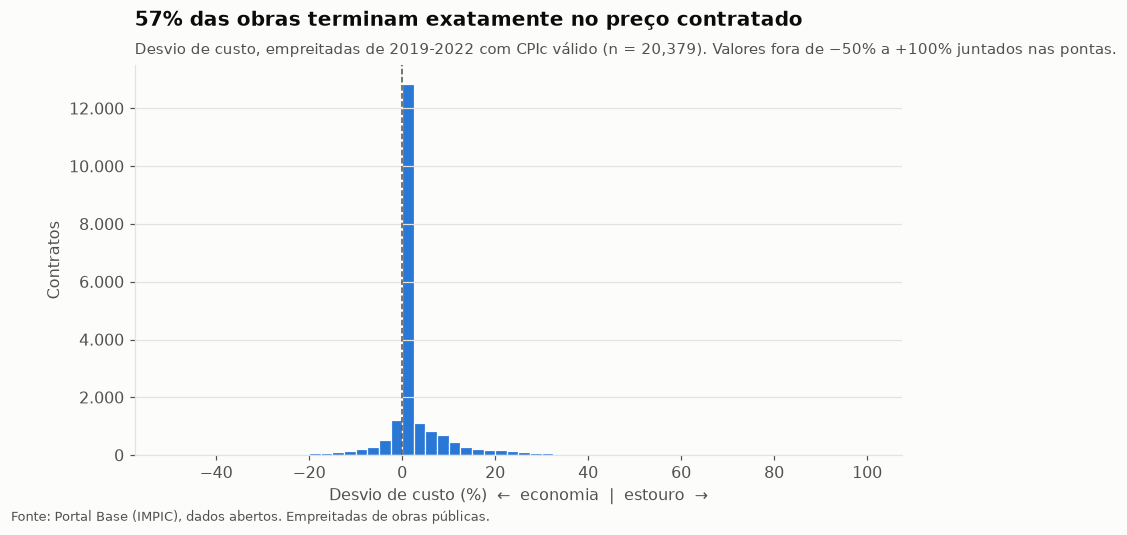

count    20379.0
mean         2.0
std          8.8
min        -50.0
10%         -1.4
25%          0.0
50%          0.0
75%          1.7
90%          9.9
max         90.3

Com estouro: 29.1% | Com economia: 14.2%
Entre os que estouraram, desvio mediano: 6.5%


In [17]:
d = custo["desvio_custo_pct"]
no_preco = (custo["CPIc"] == 1).mean()

fig, ax = plt.subplots(figsize=(9, 4.6))
bins = np.arange(-50, 102.5, 2.5)
ax.hist(d.clip(-50, 100), bins=bins, color=COR["azul"], edgecolor=COR["fundo"], linewidth=0.8)
ax.axvline(0, color=COR["texto2"], linewidth=1, linestyle="--")
ax.set_title(f"{no_preco:.0%} das obras terminam exatamente no preço contratado", pad=26)
subtitulo(ax, f"Desvio de custo, empreitadas de {JANELA[0]}-{JANELA[1]} com CPIc válido (n = {len(custo):,}). "
              "Valores fora de −50% a +100% juntados nas pontas.")
ax.set_xlabel("Desvio de custo (%)  ←  economia  |  estouro  →")
ax.set_ylabel("Contratos")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
fonte(fig)
fig.savefig(FIG / "01_distribuicao_desvio_custo.png")
plt.show()

resumo = d.describe(percentiles=[.1, .25, .5, .75, .9]).round(1)
print(resumo.to_string())
print(f"\nCom estouro: {custo['estouro'].mean():.1%} | Com economia: {(custo['CPIc'] > 1).mean():.1%}")
print(f"Entre os que estouraram, desvio mediano: {d[custo['estouro']].median():.1f}%")

## 2. A percentagem de estouro mudou ao longo dos anos?

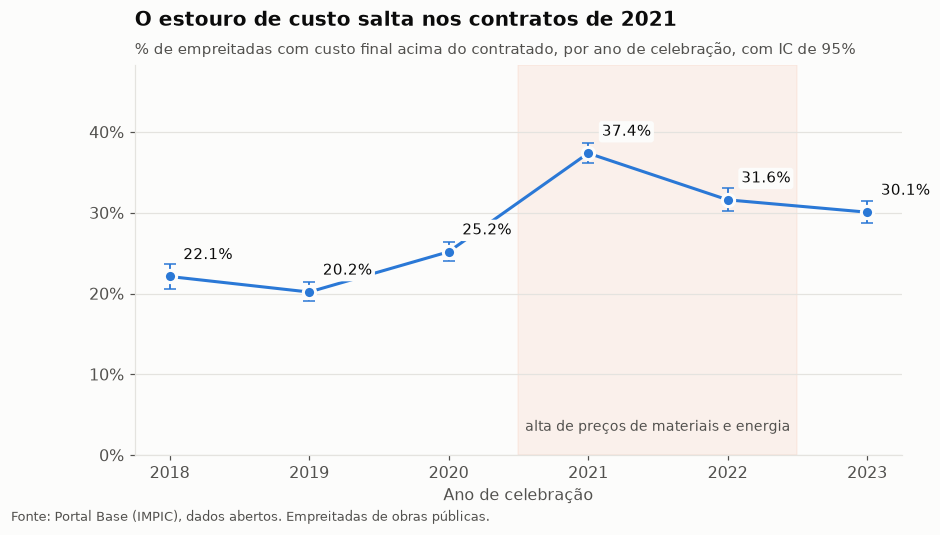

,n,estouros,pct,ic_inf,ic_sup
ano_celebracao,,,,,
2018,2813,622,22.1,20.6,23.7
2019,4384,885,20.2,19.0,21.4
2020,5590,1407,25.2,24.0,26.3
2021,6231,2329,37.4,36.2,38.6
2022,4174,1319,31.6,30.2,33.0
2023,4486,1349,30.1,28.7,31.4


In [18]:
anos = e[e["ano_celebracao"].between(2018, 2023) & e["CPIc"].notna()]
por_ano = anos.groupby("ano_celebracao").agg(n=("estouro", "size"), estouros=("estouro", "sum"))
por_ano["pct"], por_ano["ic_inf"], por_ano["ic_sup"] = wilson(por_ano["estouros"], por_ano["n"])

fig, ax = plt.subplots(figsize=(9, 4.6))
x = por_ano.index.values
ax.plot(x, por_ano["pct"], color=COR["azul"], linewidth=2, marker="o", markersize=8,
        markeredgecolor=COR["fundo"], markeredgewidth=2, zorder=3)
ax.errorbar(x, por_ano["pct"], yerr=[por_ano["pct"] - por_ano["ic_inf"], por_ano["ic_sup"] - por_ano["pct"]],
            fmt="none", ecolor=COR["azul"], elinewidth=1.2, capsize=4, zorder=2)
for xi, yi in zip(x, por_ano["pct"]):
    ax.annotate(f"{yi:.1f}%", (xi, yi), textcoords="offset points", xytext=(9, 9),
                ha="left", va="bottom", color=COR["texto"], fontsize=10, zorder=4,
                bbox=dict(boxstyle="round,pad=0.2", facecolor=COR["fundo"], edgecolor="none"))
ax.axvspan(2020.5, 2022.5, color=COR["laranja"], alpha=0.08, zorder=0)
ax.text(2021.5, 3, "alta de preços de materiais e energia", ha="center", color=COR["texto2"], fontsize=9)
ax.set_title("O estouro de custo salta nos contratos de 2021", pad=26)
subtitulo(ax, "% de empreitadas com custo final acima do contratado, por ano de celebração, com IC de 95%")
ax.set_ylim(0, max(por_ano["ic_sup"]) * 1.25)
ax.set_xticks(x)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_xlabel("Ano de celebração")
fonte(fig)
fig.savefig(FIG / "02_estouro_por_ano.png")
plt.show()
por_ano.round(1)

## 3. Porte e procedimento: o concurso público estoura mais em todas as faixas?

Cada ponto é a percentagem de estouro de um procedimento numa faixa de porte.
Pontos com menos de 100 contratos válidos não são mostrados.

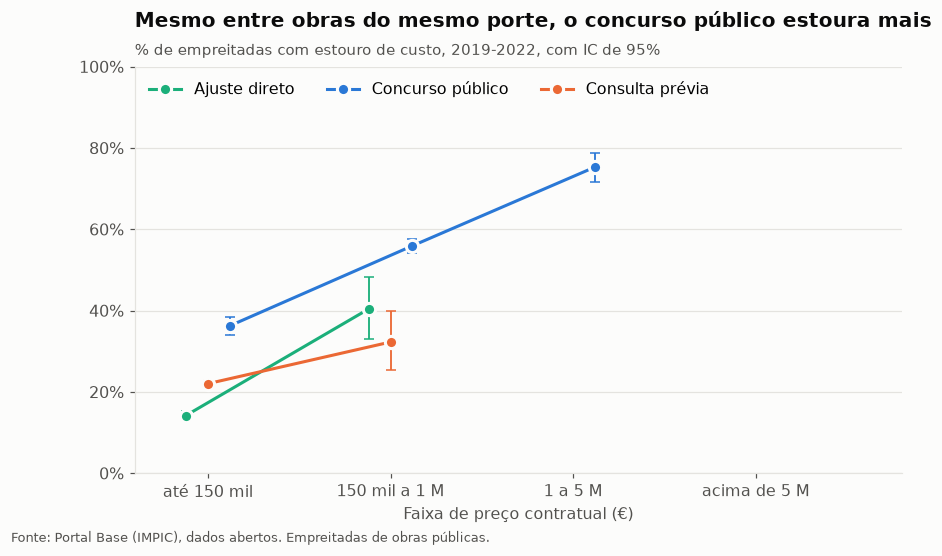

,faixa_porte,procedimento,n,estouros,pct,ic_inf,ic_sup
0,até 150 mil,Ajuste direto,4986,708,14.2,13.3,15.2
1,até 150 mil,Concurso público,1859,674,36.3,34.1,38.5
2,até 150 mil,Consulta prévia,8490,1870,22.0,21.2,22.9
3,150 mil a 1 M,Ajuste direto,151,61,40.4,32.9,48.4
4,150 mil a 1 M,Concurso público,3080,1723,55.9,54.2,57.7
5,150 mil a 1 M,Consulta prévia,158,51,32.3,25.5,39.9
7,1 a 5 M,Concurso público,543,409,75.3,71.5,78.8


In [19]:
c3 = custo[custo["tipoprocedimento"].isin(PROCEDIMENTOS)].copy()
c3["procedimento"] = c3["tipoprocedimento"].map(PROCEDIMENTOS)
grade = (c3.groupby(["faixa_porte", "procedimento"], observed=True)
           .agg(n=("estouro", "size"), estouros=("estouro", "sum")).reset_index())
grade["pct"], grade["ic_inf"], grade["ic_sup"] = wilson(grade["estouros"], grade["n"])
grade = grade[grade["n"] >= 100]

fig, ax = plt.subplots(figsize=(9, 4.8))
posicao = {f: i for i, f in enumerate(ROTULOS_FAIXA)}
deslocamento = {"Ajuste direto": -0.12, "Consulta prévia": 0.0, "Concurso público": 0.12}
for proc, g in grade.groupby("procedimento"):
    xs = g["faixa_porte"].map(posicao).astype(float) + deslocamento[proc]
    ax.plot(xs, g["pct"], color=COR_PROC[proc], linewidth=2, marker="o", markersize=8,
            markeredgecolor=COR["fundo"], markeredgewidth=2, label=proc, zorder=3)
    ax.errorbar(xs, g["pct"], yerr=[g["pct"] - g["ic_inf"], g["ic_sup"] - g["pct"]],
                fmt="none", ecolor=COR_PROC[proc], elinewidth=1.2, capsize=3, zorder=2)
ax.set_xticks(range(len(ROTULOS_FAIXA)), ROTULOS_FAIXA)
ax.set_xlim(-0.4, len(ROTULOS_FAIXA) - 0.2)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_xlabel("Faixa de preço contratual (€)")
ax.legend(loc="upper left", ncols=3)
ax.set_title("Mesmo entre obras do mesmo porte, o concurso público estoura mais", pad=26)
subtitulo(ax, f"% de empreitadas com estouro de custo, {JANELA[0]}-{JANELA[1]}, com IC de 95%")
fonte(fig)
fig.savefig(FIG / "03_estouro_porte_procedimento.png")
plt.show()
grade.round(1)

## 4. Prazo: o intervalo entre o atraso formal e o atraso até o fecho

- **Limite inferior:** % de contratos com prorrogação formal de prazo (base de modificações).
- **Limite superior:** % de contratos fechados no Portal depois do fim do prazo contratado.

A percentagem real de obras atrasadas está entre as duas linhas (decisão D7).

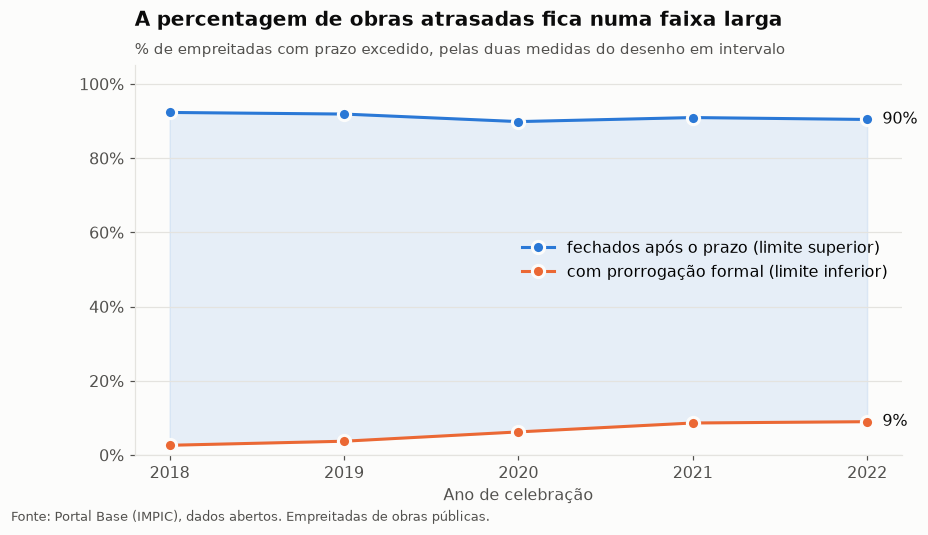

,n,prorrogados,apos,pct_formal,pct_fecho
ano_celebracao,,,,,
2018,2834,75,2617,2.6,92.3
2019,4438,166,4079,3.7,91.9
2020,5631,352,5061,6.3,89.9
2021,6310,546,5740,8.7,91.0
2022,4221,380,3818,9.0,90.5


In [20]:
pz = e[e["ano_celebracao"].between(2018, 2022) & e["valido_prazo_fecho"]].copy()
pz["prorrogado"] = pz["prorrogacao_dias"].fillna(0) > 0
pz["apos_prazo"] = pz["SPIc_fecho"] < 1
prazo_ano = pz.groupby("ano_celebracao").agg(n=("prorrogado", "size"),
                                              prorrogados=("prorrogado", "sum"),
                                              apos=("apos_prazo", "sum"))
prazo_ano["pct_formal"] = 100 * prazo_ano["prorrogados"] / prazo_ano["n"]
prazo_ano["pct_fecho"] = 100 * prazo_ano["apos"] / prazo_ano["n"]

fig, ax = plt.subplots(figsize=(9, 4.6))
x = prazo_ano.index.values
ax.fill_between(x, prazo_ano["pct_formal"], prazo_ano["pct_fecho"], color=COR["azul"], alpha=0.10, zorder=1)
for col, cor, rotulo in [("pct_fecho", COR["azul"], "fechados após o prazo (limite superior)"),
                         ("pct_formal", COR["laranja"], "com prorrogação formal (limite inferior)")]:
    ax.plot(x, prazo_ano[col], color=cor, linewidth=2, marker="o", markersize=8,
            markeredgecolor=COR["fundo"], markeredgewidth=2, label=rotulo, zorder=3)
    ax.annotate(f"{prazo_ano[col].iloc[-1]:.0f}%", (x[-1], prazo_ano[col].iloc[-1]),
                textcoords="offset points", xytext=(10, 0), va="center", color=COR["texto"])
ax.set_ylim(0, 105)
ax.set_xticks(x)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_xlabel("Ano de celebração")
ax.legend(loc="center right")
ax.set_title("A percentagem de obras atrasadas fica numa faixa larga", pad=26)
subtitulo(ax, "% de empreitadas com prazo excedido, pelas duas medidas do desenho em intervalo")
fonte(fig)
fig.savefig(FIG / "04_intervalo_prazo.png")
plt.show()
prazo_ano.round(1)

## 5. Tabela-resumo do desvio de custo por procedimento

In [21]:
def resumo_grupo(g):
    d = g["desvio_custo_pct"]
    return pd.Series({
        "contratos": len(g),
        "% com estouro": 100 * g["estouro"].mean(),
        "desvio mediano (%)": d.median(),
        "p75 (%)": d.quantile(.75),
        "p90 (%)": d.quantile(.90),
        "desvio mediano nos que estouraram (%)": d[g["estouro"]].median(),
    })

tabela = (c3.groupby("procedimento").apply(resumo_grupo, include_groups=False)
            .sort_values("% com estouro").round(1))
tabela.to_csv(RAIZ / "reports" / "tabela_desvio_por_procedimento.csv", sep=";", decimal=",", encoding="utf-8-sig")
tabela

,contratos,% com estouro,desvio mediano (%),p75 (%),p90 (%),desvio mediano nos que estouraram (%)
procedimento,,,,,,
Ajuste direto,5157.0,15.0,0.0,0.0,2.3,3.8
Consulta prévia,8655.0,22.2,0.0,0.0,5.8,5.0
Concurso público,5524.0,51.4,0.5,9.0,19.0,8.7
